## Mixed traffic interactions east of Møn (Flag 24)

### Dataset Overview
Constructed cargo, tanker, ferry, and Tourist vessel movements in open water east of Møn, including repeated crossings and varied crossing-traffic conditions.

The notebook exposes a primary table and a supporting table (`vessels.csv`).

Goal: Analyze how different vessel movements interact in the waters east of Møn and how their navigation changes across different traffic conditions.

Role: Maritime traffic analyst


Category: mixed traffic interactions east of møn

### Your Objective
Use the provided tables and visual evidence to answer the questions below and summarize the observed trajectory patterns.


## Import Necessary Libraries

This cell loads the data-analysis and visualization libraries used by the questions below.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, SVG, display
points=pd.read_csv('trajectory_points.csv')


## Load Dataset

The primary table is loaded into `df`; when available, the supporting trajectory or driver table is loaded into `user_df`.

In [ ]:
dataset_path = "trajectory_points.csv"
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv(dataset_path)

In [ ]:
user_dataset_path = "vessels.csv"
user_df = pd.read_csv(user_dataset_path)

### **Question 1**: How do vessel movement roles differ east of Møn?

#### Analysis action

Compare stable through traffic, repeated ferry crossings, and dispersed tourist-vessel excursions.

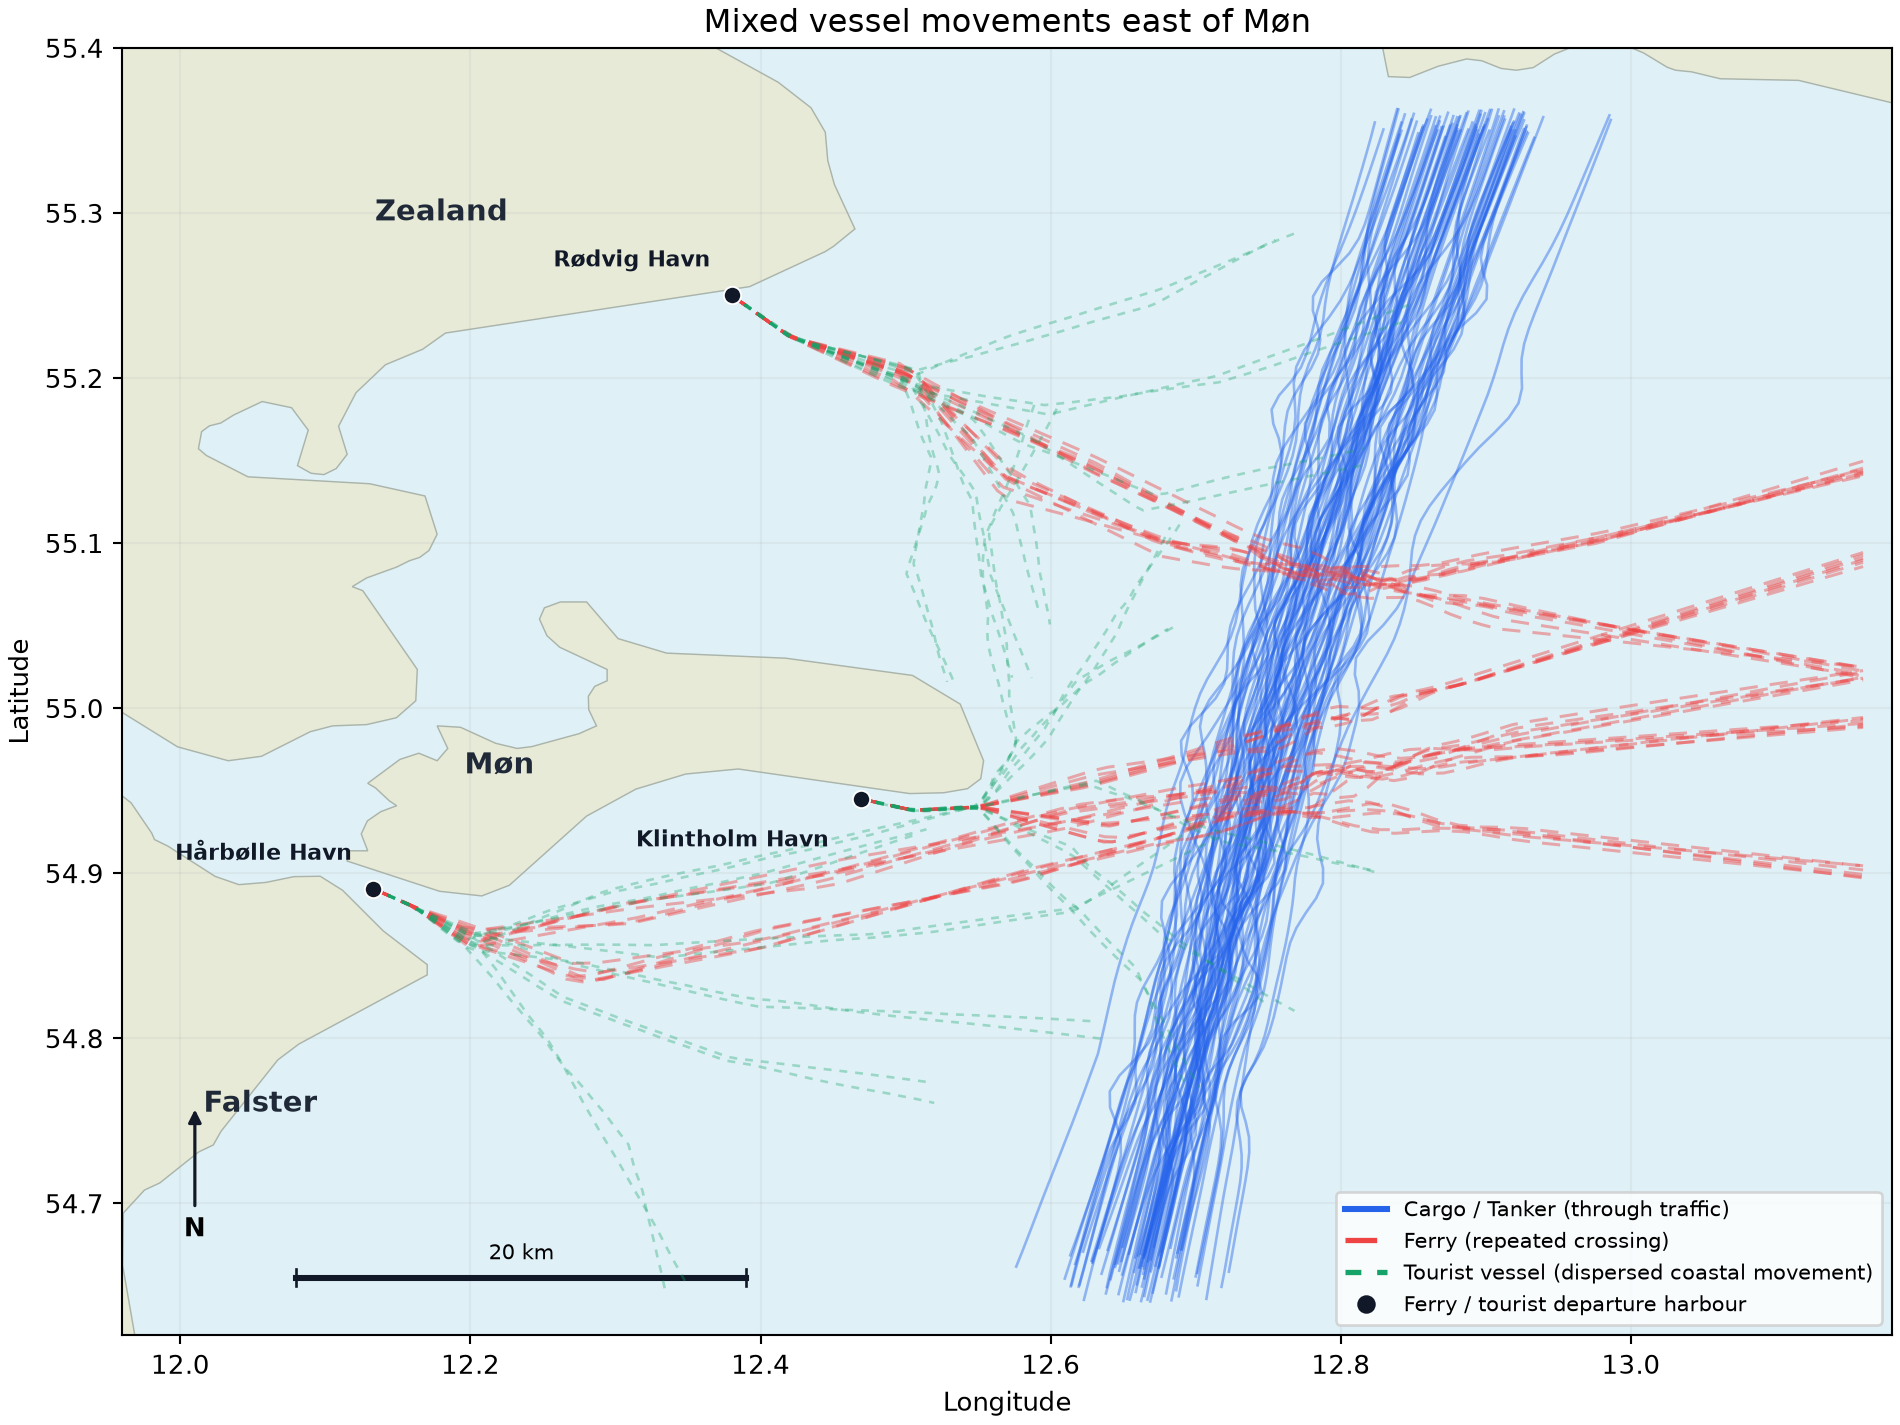

In [ ]:
import pandas as pd
df=pd.read_csv(dataset_path); print(df.groupby('ship_type').trajectory_id.nunique())
from IPython.display import Image, display
display(Image(filename='visualizations/mixed_traffic_overview.png'))


#### Generate JSON Description for the Insight

**Insight difficulty: Medium (4 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "mixed_vessel_movement_pattern",
  "insight": "Cargo and tanker vessels mainly follow stable through-traffic paths, while ferry vessels repeatedly cross these flows and tourist vessels show more dispersed movements across the area.",
  "insight_value": {
    "trajectory_counts": {
      "Cargo": 48,
      "Ferry": 40,
      "Tourist vessel": 36,
      "Tanker": 32
    },
    "median_spatial_span_deg": {
      "Cargo": {
        "lon_span": 0.231,
        "lat_span": 0.693
      },
      "Ferry": {
        "lon_span": 0.78,
        "lat_span": 0.149
      },
      "Tanker": {
        "lon_span": 0.23,
        "lat_span": 0.701
      },
      "Tourist vessel": {
        "lon_span": 0.325,
        "lat_span": 0.123
      }
    }
  },
  "plot": {
    "plot_type": "type_role_map",
    "title": "Mixed Traffic East of Møn",
    "file": "visualizations/mixed_traffic_overview.png",
    "description": "Compare stable through traffic, repeated ferry crossings, and dispersed tourist-vessel excursions."
  },
  "question": "How do vessel movement roles differ east of Møn?",
  "actionable_insight": "Compare stable through traffic, repeated ferry crossings, and dispersed tourist-vessel excursions.",
  "code": "import pandas as pd\ndf=pd.read_csv(dataset_path); print(df.groupby('ship_type').trajectory_id.nunique())",
  "insight_type": "overall_pattern",
  "difficulty_level": 4,
  "difficulty_label": "medium",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "ship_type",
    "gps_position",
    "vessel_id",
    "trajectory_timestamp"
  ]
}

### **Question 2**: How do ferry movements change while crossing the main traffic flow?

#### Analysis action

Compare speed and successive COG variation inside and outside the crossing-interaction phase.

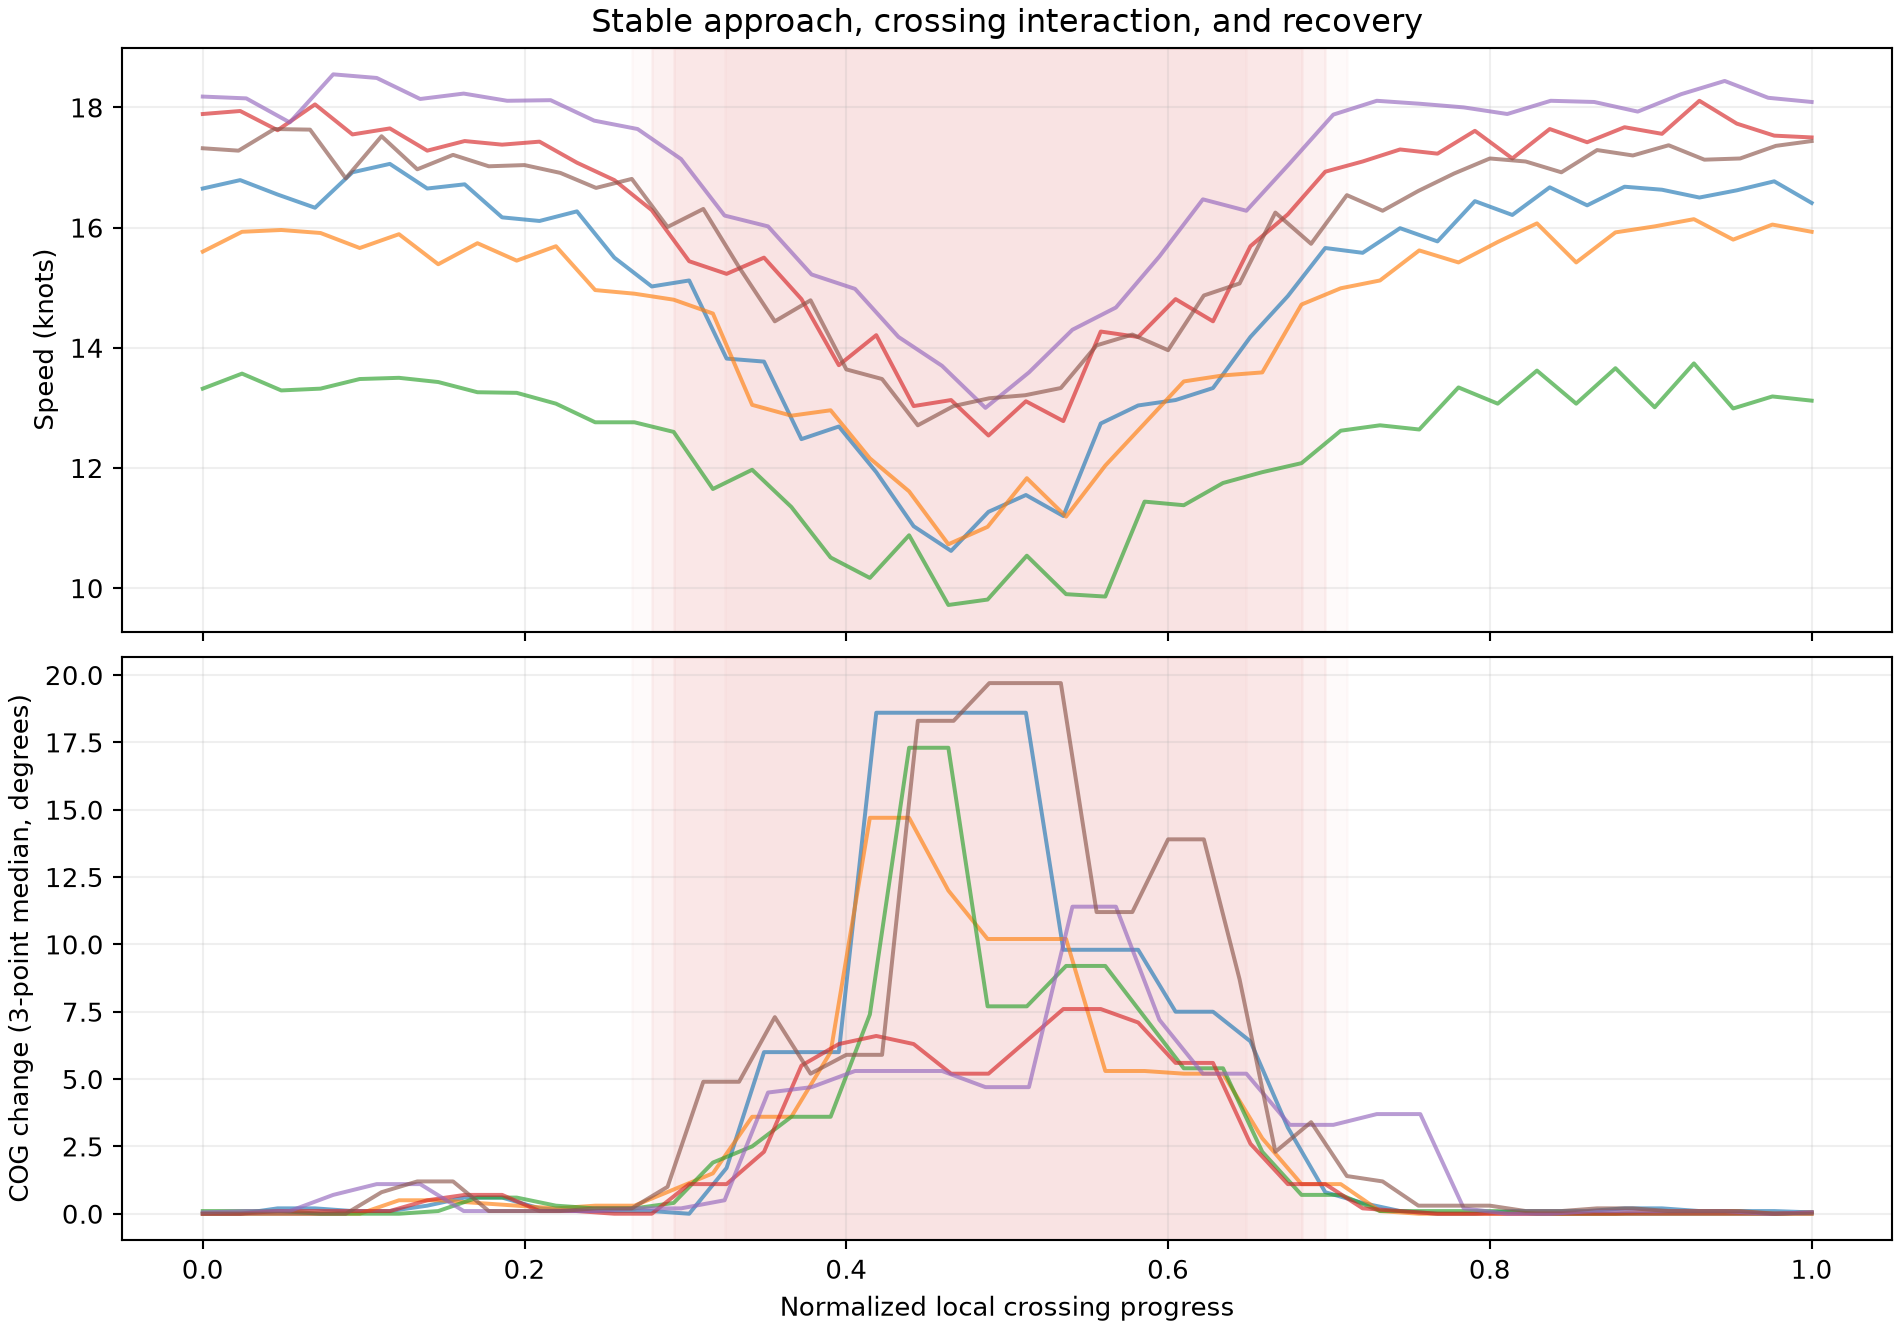

In [ ]:
import pandas as pd
df=pd.read_csv(dataset_path); print(df[df.ship_type.eq('Ferry')].groupby('movement_phase').sog_knots.describe())
from IPython.display import Image, display
display(Image(filename='visualizations/ferry_crossing_dynamics.png'))


#### Generate JSON Description for the Insight

**Insight difficulty: Very High (6 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "ferry_crossing_phase",
  "insight": "Repeated ferry vessel crossings typically contain a short phase of reduced speed and increased COG variation near the main traffic flow, followed by a return to more stable movement after the crossing.",
  "insight_value": {
    "speed_knots": {
      "crossing interaction": 12.98,
      "stable ferry movement": 15.77
    },
    "cog_change_deg": {
      "crossing interaction": 5.85,
      "stable ferry movement": 0.1
    }
  },
  "plot": {
    "plot_type": "phase_profile",
    "title": "Ferry Crossing Dynamics",
    "file": "visualizations/ferry_crossing_dynamics.png",
    "description": "Compare speed and successive COG variation inside and outside the crossing-interaction phase."
  },
  "question": "How do ferry movements change while crossing the main traffic flow?",
  "actionable_insight": "Compare speed and successive COG variation inside and outside the crossing-interaction phase.",
  "code": "import pandas as pd\ndf=pd.read_csv(dataset_path); print(df[df.ship_type.eq('Ferry')].groupby('movement_phase').sog_knots.describe())",
  "insight_type": "temporal_dynamics",
  "difficulty_level": 6,
  "difficulty_label": "very high",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "ship_type",
    "gps_position",
    "point_speed",
    "course_over_ground",
    "vessel_id",
    "trajectory_timestamp"
  ]
}

### **Question 3**: How does crossing activity affect through-traffic stability?

#### Analysis action

Classify traffic using concurrent crossing-vessel rates, then compare individual trajectories and group distributions.

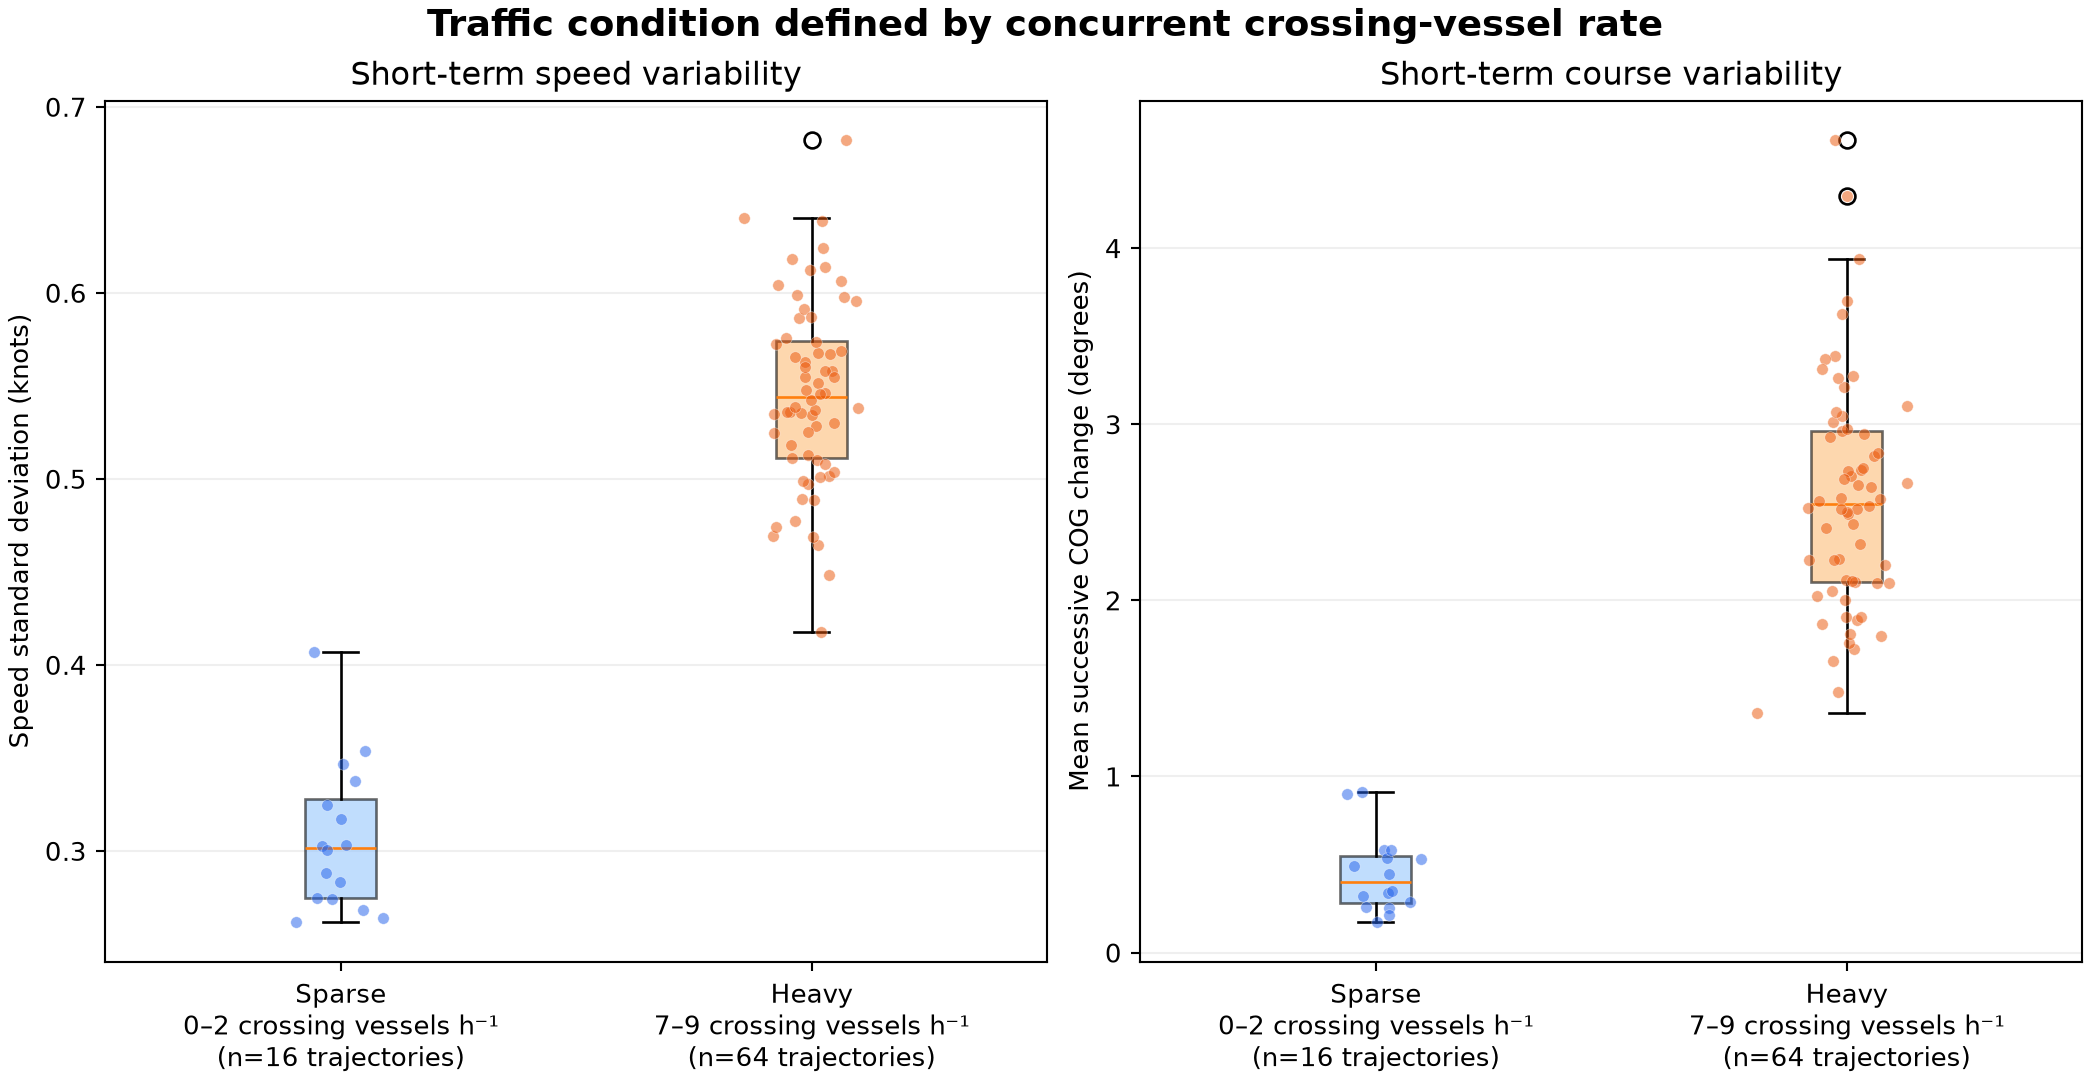

In [ ]:
import pandas as pd
df=pd.read_csv(dataset_path); x=df[df.ship_type.isin(['Cargo','Tanker'])]; print(x.groupby(['traffic_condition','trajectory_id']).sog_knots.std().groupby(level=0).describe())
from IPython.display import Image, display
display(Image(filename='visualizations/crossing_traffic_adjustments.png'))


#### Generate JSON Description for the Insight

**Insight difficulty: Very High (6 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "crossing_traffic_adjustments",
  "insight": "Through-traffic vessels show more frequent short-term speed and course adjustments during periods with heavier crossing traffic, while their movement remains more stable when crossing activity is sparse.",
  "insight_value": {
    "traffic_condition_definition": {
      "sparse crossing": "0–2 crossing vessels per hour",
      "heavy crossing": "7–9 crossing vessels per hour"
    },
    "trajectory_sample_sizes": {
      "heavy crossing": 64,
      "sparse crossing": 16
    },
    "median_adjustment_events": {
      "heavy crossing": 5,
      "sparse crossing": 0
    },
    "median_variability": {
      "heavy crossing": {
        "speed_sd": 0.54,
        "turn_change": 2.55
      },
      "sparse crossing": {
        "speed_sd": 0.3,
        "turn_change": 0.4
      }
    }
  },
  "plot": {
    "plot_type": "condition_comparison",
    "title": "Through-traffic Adjustments by Crossing Activity",
    "file": "visualizations/crossing_traffic_adjustments.png",
    "description": "Classify traffic using concurrent crossing-vessel rates, then compare individual trajectories and group distributions."
  },
  "question": "How does crossing activity affect through-traffic stability?",
  "actionable_insight": "Classify traffic using concurrent crossing-vessel rates, then compare individual trajectories and group distributions.",
  "code": "import pandas as pd\ndf=pd.read_csv(dataset_path); x=df[df.ship_type.isin(['Cargo','Tanker'])]; print(x.groupby(['traffic_condition','trajectory_id']).sog_knots.std().groupby(level=0).describe())",
  "insight_type": "factor_relationship",
  "difficulty_level": 6,
  "difficulty_label": "very high",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "ship_type",
    "trajectory_timestamp",
    "gps_position",
    "point_speed",
    "course_over_ground",
    "vessel_id"
  ]
}

### Summary of Findings (Flag 24)

Cargo and tanker vessels mainly follow stable through-traffic paths, while ferry vessels repeatedly cross these flows and tourist vessels show more dispersed movements across the area. Repeated ferry vessel crossings typically contain a short phase of reduced speed and increased COG variation near the main traffic flow, followed by a return to more stable movement after the crossing. Through-traffic vessels show more frequent short-term speed and course adjustments during periods with heavier crossing traffic, while their movement remains more stable when crossing activity is sparse.
